In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose

In [3]:
df = pd.read_csv('Global_Superstore.csv')
#data was given through Project 1: Global Superstore Dataset
#available on Kaggle - no link to the website provided

##### 0.0 Profiling Data

In [4]:
df.head(15)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,40098,CA-2014-AB10015140-41954,11/11/2014,11/13/2014,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,TEC-PH-5816,Technology,Phones,Samsung Convoy 3,221.98,2,0.0,62.15,40.77,High
1,26341,IN-2014-JR162107-41675,2/5/2014,2/7/2014,Second Class,JR-162107,Justin Ritter,Corporate,NaN,Wollongong,...,FUR-CH-5379,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",3709.40,9,0.1,-288.77,923.63,Critical
2,25330,IN-2014-CR127307-41929,10/17/2014,10/18/2014,First Class,CR-127307,Craig Reiter,Consumer,NaN,Brisbane,...,TEC-PH-5356,Technology,Phones,"Nokia Smart Phone, with Caller ID",5175.17,9,0.1,919.97,915.49,Medium
3,13524,ES-2014-KM1637548-41667,1/28/2014,1/30/2014,First Class,KM-1637548,Katherine Murray,Home Office,NaN,Berlin,...,TEC-PH-5267,Technology,Phones,"Motorola Smart Phone, Cordless",2892.51,5,0.1,-96.54,910.16,Medium
4,47221,SG-2014-RH9495111-41948,11/5/2014,11/6/2014,Same Day,RH-9495111,Rick Hansen,Consumer,NaN,Dakar,...,TEC-CO-6011,Technology,Copiers,"Sharp Wireless Fax, High-Speed",2832.96,8,0.0,311.52,903.04,Critical
5,22732,IN-2014-JM156557-41818,6/28/2014,7/1/2014,Second Class,JM-156557,Jim Mitchum,Corporate,NaN,Sydney,...,TEC-PH-5842,Technology,Phones,"Samsung Smart Phone, with Caller ID",2862.68,5,0.1,763.28,897.35,Critical
6,30570,IN-2012-TS2134092-41219,11/6/2012,11/8/2012,First Class,TS-2134092,Toby Swindell,Consumer,NaN,Porirua,...,FUR-CH-5378,Furniture,Chairs,"Novimex Executive Leather Armchair, Adjustable",1822.08,4,0.0,564.84,894.77,Critical
7,31192,IN-2013-MB1808592-41378,4/14/2013,4/18/2013,Standard Class,MB-1808592,Mick Brown,Consumer,NaN,Hamilton,...,FUR-TA-3764,Furniture,Tables,"Chromcraft Conference Table, Fully Assembled",5244.84,6,0.0,996.48,878.38,High
8,40099,CA-2014-AB10015140-41954,11/11/2014,11/13/2014,First Class,AB-100151402,Aaron Bergman,Consumer,73120.0,Oklahoma City,...,FUR-BO-5957,Furniture,Bookcases,"Sauder Facets Collection Library, Sky Alder Fi...",341.96,2,0.0,54.71,25.27,High
9,36258,CA-2012-AB10015140-40974,3/6/2012,3/7/2012,First Class,AB-100151404,Aaron Bergman,Consumer,98103.0,Seattle,...,FUR-CH-4421,Furniture,Chairs,"Global Push Button Manager's Chair, Indigo",48.71,1,0.2,5.48,11.13,High


All the below mentioned columns are assesed on the FIRST 15 reccords.

Ship Mode: has three categories: First Class, Seccond Class, Same Day

Postal Code: has a lot of NaN values - need to see if these are missing values. Could be an export issue.
            Can observe decimans in the numbers - presuming the data type is float - will need to be changed if used in analysis capacity.
            
Segment: has three categories: Consumer, Corporate, Home Office

Order Priority: has three categories: Medium, High, Critical

There are several given alternatives bby which we can aggrigate the dataset.

In [5]:
df.shape

(1000, 24)

Only 1000 records - we're good to assess this as sample sized dataset.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          1000 non-null   int64  
 1   Order ID        1000 non-null   object 
 2   Order Date      1000 non-null   object 
 3   Ship Date       1000 non-null   object 
 4   Ship Mode       1000 non-null   object 
 5   Customer ID     1000 non-null   object 
 6   Customer Name   1000 non-null   object 
 7   Segment         1000 non-null   object 
 8   Postal Code     194 non-null    float64
 9   City            1000 non-null   object 
 10  State           1000 non-null   object 
 11  Country         1000 non-null   object 
 12  Region          1000 non-null   object 
 13  Market          1000 non-null   object 
 14  Product ID      1000 non-null   object 
 15  Category        1000 non-null   object 
 16  Sub-Category    1000 non-null   object 
 17  Product Name    1000 non-null   ob

Massive ammount of data missing in the postal code column, and it is in float dtype - is an issue for potential geographic mapping. If this avenue was to be persuited in depth, new data will certainly need to be collected. 

Might be an issue with the entry, will need to be investigated further at the back end.

Order Date - currently object data type (dtype)
Ship Date - currently object dtype
            both need to be converted into datetime.
City - currently object dtype
State - currently object dtype
Country - currently object dtype
Region - currently object dtype
        if wanting to investigate in future analysis, will need to be transformed into respective georgafic fields
Sales - currently float dtype
Quantity - currently integer dtype
Discount - currently float dtype
Profit - currently float dtype
         are all in appropriate numerical dtype

All in all, from the dtype perspective the set is pretty good to use - only critical columns that need appropriate conversions are the Order and Ship date, for timeanalysis and/or visualisations we might pursue.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Row ID,1000.0,25079.328000,12897.726632,58.00,15118.7500,25084.5000,34524.00000,51284.00
Postal Code,194.0,53966.170103,33734.306466,2920.00,19134.0000,60564.0000,88187.50000,98198.00
Sales,1000.0,1710.971470,1259.239238,1.91,826.9075,1585.1150,2477.81250,9892.74
Quantity,1000.0,5.558000,2.718460,1.00,4.0000,5.0000,7.00000,14.00
Discount,1000.0,0.092840,0.148666,0.00,0.0000,0.0000,0.15000,0.80
Profit,1000.0,288.920440,574.504782,-3059.82,10.0375,190.6850,518.87250,4946.37
Shipping Cost,1000.0,272.384897,176.160716,1.07,209.8275,258.8975,351.07025,923.63


Sales: clear wide range in sales amounts, the stadard deviation is quiet extreme

Quantity: much more moderate range in number comparatively speaking, with presumably most people ordering thin 3 std of the mean.

Profit: the min being the negative is concerning, this defively need to be investigated - why was 100% discount being given? Potential point of further investigation. Not entirely relevant to current analysis.

Overall, these numbers will need to be worked with further into the different segments for deeper analysis, as the current outliers clearly heavily sway the results - could be interesting to look into the various segments of *Segment, Ship Mode and Order Priority*.

In [8]:
df.tail(15)
#checking for errors in the data

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Postal Code,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
985,13479,IT-2014-JB1592548-41789,5/30/2014,6/4/2014,Standard Class,JB-1592548,Joni Blumstein,Consumer,NaN,Trier,...,TEC-PH-5268,Technology,Phones,"Motorola Smart Phone, Full Size",2570.76,4,0.00,976.80,204.640,Medium
986,16812,ES-2014-TW21025139-41807,6/17/2014,6/20/2014,Second Class,TW-21025139,Tamara Willingham,Home Office,NaN,Leeds,...,TEC-CO-4776,Technology,Copiers,"HP Fax Machine, Laser",1199.76,4,0.00,479.88,204.430,Medium
987,21554,IN-2015-GW1460527-42089,3/26/2015,3/29/2015,Second Class,GW-1460527,Giulietta Weimer,Consumer,NaN,Luoyang,...,TEC-CO-6009,Technology,Copiers,"Sharp Wireless Fax, Color",3216.24,9,0.00,96.39,204.360,High
988,1702,US-2012-SC2072518-41166,9/14/2012,9/16/2012,First Class,SC-2072518,Steven Cartwright,Consumer,NaN,Petrópolis,...,FUR-TA-3341,Furniture,Tables,"Barricks Computer Table, Fully Assembled",1274.24,5,0.20,-127.46,204.313,High
989,19853,ES-2013-LR1691544-41537,9/20/2013,9/25/2013,Second Class,LR-1691544,Lena Radford,Consumer,NaN,Vantaa,...,OFF-AP-3875,Office Supplies,Appliances,"Cuisinart Stove, White",2145.72,4,0.00,364.68,204.290,Medium
990,33274,CA-2012-AS10225140-41199,10/17/2012,10/19/2012,Second Class,AS-102251408,Alan Schoenberger,Corporate,36116.0,Montgomery,...,FUR-CH-4429,Furniture,Chairs,"Global Wood Trimmed Manager's Task Chair, Khaki",545.88,6,0.00,70.96,29.900,Medium
991,30193,IN-2012-PB19210127-41259,12/16/2012,12/19/2012,First Class,PB-19210127,Phillip Breyer,Corporate,NaN,Taipei,...,FUR-CH-5454,Furniture,Chairs,"Office Star Swivel Stool, Adjustable",882.15,5,0.00,114.60,203.920,Critical
992,33950,CA-2015-AS10225140-42265,9/18/2015,9/22/2015,Second Class,AS-102251404,Alan Schoenberger,Corporate,84604.0,Provo,...,OFF-PA-4465,Office Supplies,Paper,Green Bar Computer Printout Paper,164.88,3,0.00,80.79,12.730,Medium
993,14079,ES-2012-FO1430545-41141,8/20/2012,8/20/2012,Same Day,FO-1430545,Frank Olsen,Consumer,NaN,Noisy-le-Grand,...,OFF-ST-6047,Office Supplies,Storage,"Smead Lockers, Industrial",895.05,5,0.10,178.95,203.670,High
994,47959,SY-2013-SV10815126-41541,9/24/2013,9/28/2013,Standard Class,SV-10815126,Stuart Van,Corporate,NaN,Homs,...,TEC-PH-3807,Technology,Phones,"Cisco Smart Phone, with Caller ID",1570.18,4,0.40,104.62,203.610,High


Following columns are assessed on the LAST 15 rows in the data set.

RowID: some of the numbers are 4 digits - either the data is not in its natural order, or there is an issue and the table constraints need to be looked into - would need to be looked into further. 

Postal Code: as mentioned before, has most information missing.

These columns need to be investigated for quality control - is this an export error? Data entry? or a matter of constraints application in the database.

#### 0.1 Cleaning and Conversion

##### Areas of Focus 

- Which product categories are the most profitable?
- Are there any noticeable trends in sales over time?
- How do sales and profits vary by region?
- Is there a correlation between discount and profit?

Fields needed for the current objective(s):
Order ID
Order Date - need dtype conversion
Ship Date - need dtype conversion
Ship Mode
Customer ID
Segment
Region 

*Product ID
Category 
Sub-Category 
Product Name  
Sales          
Quantity        
Discount
Profit
Shipping Cost
Order Priority* 
these columns are currently not needed for the scope of this analysis as set out by our focus questions, meaning we can discard them for our purpouses.

In [9]:
#checking for NaN's and health of the columns
countofnan = df.isna().sum()
percentofnan = df.isna().mean()

print(f'Count of NaN per column: {countofnan}\n')
print(f'Percentage of NaN per column: {percentofnan}')

Count of NaN per column: Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Postal Code       806
City                0
State               0
Country             0
Region              0
Market              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Quantity            0
Discount            0
Profit              0
Shipping Cost       0
Order Priority      0
dtype: int64

Percentage of NaN per column: Row ID            0.000
Order ID          0.000
Order Date        0.000
Ship Date         0.000
Ship Mode         0.000
Customer ID       0.000
Customer Name     0.000
Segment           0.000
Postal Code       0.806
City              0.000
State             0.000
Country           0.000
Region            0.000
Market            0.000
Product ID        0.000
Category          0.000
Sub-Category      0

In [10]:
#dropping NaN column - Postal Code
df = df.drop(columns= ['Postal Code'], inplace= True)

Dropping the unnecessary columns - Row ID, City, State, Country, Market, Ship Mode, Segment and Order Priority.
We are also removing Customer Name column, as this is sencitive information.

In [236]:
df.drop(columns=['Row ID', 'City', 'State', 'Country', 'Market', 'Customer Name','Ship Mode', 'Segment', 'Order Priority'], inplace= True)

df.reset_index(drop=True, inplace= True)

In [237]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order ID       1000 non-null   object 
 1   Order Date     1000 non-null   object 
 2   Ship Date      1000 non-null   object 
 3   Customer ID    1000 non-null   object 
 4   Region         1000 non-null   object 
 5   Product ID     1000 non-null   object 
 6   Category       1000 non-null   object 
 7   Sub-Category   1000 non-null   object 
 8   Product Name   1000 non-null   object 
 9   Sales          1000 non-null   float64
 10  Quantity       1000 non-null   int64  
 11  Discount       1000 non-null   float64
 12  Profit         1000 non-null   float64
 13  Shipping Cost  1000 non-null   float64
dtypes: float64(4), int64(1), object(9)
memory usage: 109.5+ KB


In [238]:
#Checking for duplicates
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool

No existing duplicates found in the data frame.

In [239]:
#converting our dates columns into datetime d.t.
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce')

In [240]:
#double checking that our conversion is correct
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order ID       1000 non-null   object        
 1   Order Date     1000 non-null   datetime64[ns]
 2   Ship Date      1000 non-null   datetime64[ns]
 3   Customer ID    1000 non-null   object        
 4   Region         1000 non-null   object        
 5   Product ID     1000 non-null   object        
 6   Category       1000 non-null   object        
 7   Sub-Category   1000 non-null   object        
 8   Product Name   1000 non-null   object        
 9   Sales          1000 non-null   float64       
 10  Quantity       1000 non-null   int64         
 11  Discount       1000 non-null   float64       
 12  Profit         1000 non-null   float64       
 13  Shipping Cost  1000 non-null   float64       
dtypes: datetime64[ns](2), float64(4), int64(1), object(7)
memory usage: 109.5

In [241]:
#establishing timeline for our data set through arranging it by order date earliest to latest
date_ordered = df[['Order Date', 'Ship Date']].sort_values(by='Order Date')
print(date_ordered)

    Order Date  Ship Date
328 2012-01-08 2012-01-13
562 2012-01-08 2012-01-12
39  2012-01-10 2012-01-11
399 2012-01-21 2012-01-27
764 2012-01-24 2012-01-24
..         ...        ...
640 2015-12-29 2015-12-31
431 2015-12-29 2015-12-31
748 2015-12-30 2016-01-02
656 2015-12-31 2016-01-03
704 2015-12-31 2016-01-01

[1000 rows x 2 columns]


Though this we have established that our data ranges the years of:
2012, 2013, 2014 and 2015
with shipping dates going into the begining January of 2016.

#### 1. Operational Performance Analysis

In [242]:
#calculating: Total Sales, Total Sales Per Category, Total Sales Per Sub-Category
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()

print(f'Total Sales: £{total_sales:,.2f}')
print(f'Total Profit: £{total_profit:,.2f}')

#calculating performance per Category, Sub-Category and top 5 Products.
category_totals = df.groupby('Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
subcategory_totals = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)
top5_products_by_totals =  df.groupby('Product Name')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).head(5)
bottom5_products_by_totals =  df.groupby('Product Name')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False).tail(5)

#regional performance summary
performance_by_region = df.groupby('Region')[['Sales', 'Profit']].sum().sort_values(by='Sales', ascending=False)

#format dictionary for concistency
currency_format = {'Sales': '£{:,.2f}', 'Profit': '£{:,.2f}'}

print("\nPerformance Totals by Category")
display(category_totals.style.format(currency_format))
print("\nPerformance Totals by Sub-Category")
display(subcategory_totals.style.format(currency_format))
print("\nPerformance Totals by Region")
display(performance_by_region.style.format(currency_format))
print("\nTop 5 Products")
display(top5_products_by_totals.style.format(currency_format))
print("\nBottom 5 Products")
display(bottom5_products_by_totals.style.format(currency_format))

Total Sales: £1,710,971.47
Total Profit: £288,920.44

Performance Totals by Category


,Sales,Profit
Category,,
Technology,"£756,983.02","£145,068.68"
Furniture,"£601,492.31","£82,188.95"
Office Supplies,"£352,496.14","£61,662.81"



Performance Totals by Sub-Category


,Sales,Profit
Sub-Category,,
Phones,"£417,939.31","£75,119.47"
Appliances,"£289,711.30","£48,518.99"
Bookcases,"£240,688.73","£45,483.14"
Copiers,"£231,104.67","£52,315.19"
Chairs,"£179,648.44","£23,245.88"
Tables,"£179,292.88","£13,051.69"
Machines,"£71,366.87","£8,992.06"
Storage,"£37,592.32","£4,490.04"
Accessories,"£36,572.17","£8,641.96"



Performance Totals by Region


,Sales,Profit
Region,,
Western Europe,"£259,576.28","£32,783.40"
Oceania,"£220,809.08","£33,777.56"
Southern Asia,"£205,466.26","£37,536.60"
Eastern Asia,"£193,590.60","£37,911.16"
Southeastern Asia,"£147,337.60","£10,561.80"
Central America,"£140,966.21","£21,741.95"
Northern Europe,"£103,888.63","£23,552.73"
Southern Europe,"£94,441.11","£20,557.50"
South America,"£64,550.54","£7,723.58"



Top 5 Products


,Sales,Profit
Product Name,,
"Motorola Smart Phone, Full Size","£48,542.52","£13,088.28"
"Apple Smart Phone, Full Size","£42,303.44","£2,651.09"
"Cisco Smart Phone, Full Size","£41,325.20","£9,662.99"
"Nokia Smart Phone, Full Size","£27,661.97","£5,765.12"
"Samsung Smart Phone, Cordless","£25,438.59",£920.16



Bottom 5 Products


,Sales,Profit
Product Name,,
Newell 323,£3.36,£0.87
Acco Hanging Data Binders,£3.05,£1.07
"OIC #2 Pencils, Medium Soft",£3.01,£0.34
Hoover Replacement Belt for Commercial Guardsman Heavy-Duty Upright Vacuum,£2.22,£0.67
Insertable Tab Indexes For Data Binders,£1.91,£-3.24


Looking at the numbers there is a significant drop between Sales and Profit numbers, between **Total Sales to Total Profits the difference is £142,2051.03** which is is alarming. Looking into the Sub-Categories, we can see **Supplies: Sales: £2,037.92, Profit: -£89.85**. These numbers that we do not want to see. 
Natural question is what are the proffit margins within these various breakdowns - knowing the percentage will enable us to easier see the differences in our sales/profits to see more clear results for our breakdowns for our base view. 

For the initial view, we'll be using **median** for our measure of central tendency. We're doing this primarily to gain the insight into an average profit margin on our Categories, Sub-Categories and Regions. For our Top/Bottom 5 products, we will be using the standard **mean**, as both the low and the high volume of sales can be significant at such a high level of granularity.

In [243]:
#breakdown out data by Category, Sub-Category and Product Name to calculate the profit margin(s)
category_totals = df.groupby('Category')[['Profit', 'Sales']].sum()
category_by_profitmargin = ((category_totals['Profit']/category_totals['Sales'])*100).sort_values(ascending=False)

subcategory_totals = df.groupby('Sub-Category')[['Profit', 'Sales']].sum()
subcateogry_by_profitmargin = ((subcategory_totals['Profit']/subcategory_totals['Sales'])*100).sort_values(ascending=False)

region_totals = df.groupby('Region')[['Profit', 'Sales']].sum()
region_by_profitmargin = ((region_totals['Profit']/region_totals['Sales'])*100).sort_values(ascending=False)

#grouping product sums 
product_totals = df.groupby('Product Name')[['Profit', 'Sales']].sum()

#dynamic filtering to identify the median sales value of the dataset
median_sales_threshold = df['Sales'].median()

#filtering the totals with the median sales threshold inorder to exclude the extremes
filtered_product_totals = product_totals[product_totals['Sales'] >= median_sales_threshold]

#calculating profit margin percentage on the stable products
product_by_profitmargin = ((filtered_product_totals['Profit'] / filtered_product_totals['Sales']) * 100).sort_values(ascending=False)

#dynamic filtering by mean for top/bottom 5 products
mean_sales_threshold = df['Sales'].mean()

filtered_product_totals_mean = product_totals[product_totals['Sales'] >= mean_sales_threshold]

product_by_profitmargin_mean = ((filtered_product_totals_mean['Profit'] / filtered_product_totals_mean['Sales']) * 100).sort_values(ascending=False)

#applying out calculations to the data
print("Categories by Profit Margin")
for cat, margin in category_by_profitmargin.items():
    print(f'{cat} | {margin:.1f}%')

print("\nSub-Categories by Profit Margin")
for sub, margin in subcateogry_by_profitmargin.items():
    print(f'{sub} | {margin:.1f}%')

print("\nRegions by Profit Margin")
for reg, margin in region_by_profitmargin.items():
    print(f'{reg} | {margin:.1f}%')

print("\nTop 5 Products by Profit Margin")
for prod, margin in product_by_profitmargin_mean.head(5).items():
    print(f'{prod} | {margin:.1f}%')

print("\nBottom 5 Products by Profit Margin")
for prod, margin in product_by_profitmargin_mean.tail(5).items():
    print(f'{prod} | {margin:.1f}%')

Categories by Profit Margin
Technology | 19.2%
Office Supplies | 17.5%
Furniture | 13.7%

Sub-Categories by Profit Margin
Fasteners | 48.0%
Paper | 44.4%
Labels | 39.9%
Binders | 37.6%
Envelopes | 36.8%
Accessories | 23.6%
Copiers | 22.6%
Furnishings | 21.9%
Art | 21.2%
Bookcases | 18.9%
Phones | 18.0%
Appliances | 16.7%
Chairs | 12.9%
Machines | 12.6%
Storage | 11.9%
Tables | 7.3%
Supplies | -4.4%

Regions by Profit Margin
Central US | 33.0%
Central Africa | 28.6%
North Africa | 28.2%
Eastern Europe | 26.8%
Eastern Africa | 24.7%
Canada | 24.1%
Northern Europe | 22.7%
Southern Africa | 21.9%
Southern Europe | 21.8%
Eastern US | 20.8%
Eastern Asia | 19.6%
Southern Asia | 18.3%
Caribbean | 17.8%
Southern US | 16.6%
Western Asia | 15.8%
Central America | 15.4%
Oceania | 15.3%
Western US | 14.7%
Western Europe | 12.6%
South America | 12.0%
Western Africa | 8.3%
Southeastern Asia | 7.2%

Top 5 Products by Profit Margin
GBC Ibimaster 500 Manual ProClick Binding System | 50.0%
Dania Classic 

From looking at these margins, we can see both decent profits with our **top performing products sitting on 50%-48%**.

Though all of our **categories are just below 20%** with **Furniture falling furtherst behind at 13.7%** margin. This would indicate that there might be an operational cost that we do not see. 

Our overall **regions are steady in performance** none of them are particularly outstanding with the **strongest performing region being Central US with 33.0%** and **weakest regions Western Africa and Southeastern Asia lying in the single digits - 8.3% and 7.2% respectively**.

The most allarming numbers we see is in the **bottom performing products, all of which are in the negative margin**, with the product with the **highest negative profit margin: Barricks Conference Table, Rectangular, profit margin: -126.7%.**

In conclusion we can see that though our overal volume of sales is decent, the organisation is not very efficient in its profit gains. Which means we should look into the factors that are pulling these figures down and we most definitively need to look into the bottom products as in some cases we look to be loosing above 100% of their value.

**Further Questions**:
What are the quantities that we are selling of the highest vs lowest performers? One would expect that the cheapest supplies will be performing at least in some profit.
How are discounts applied to the various products, resulting in negative profit? 
What is the discount percentage applied per category? Are there any outliers? Any particular category/sub-category/product that stands out?
Is there any particular time periods that are significantly affecting the performance? eg summer sale/winter sale/region specific sale?

Now that we can see that the profits are draged down - we should take a look as to what can be affecting these numbers.

*We do need to keep in mind that this is a limited, sample data set.*

#### 1.1 Operational Friction Analysis

To start off we'll be looking at the drag factors that we have access to. In the dataset we have a few columns that we can look at: *quantities sold, discounts and shipping costs*. 
Looking at sub-category level will give us enough grain in our insights to make the calculations and visualisations significant enough to drive decisions, but not overwhelm the stakeholders with detail at this level of analysis. This being a sample sized dataset and with only limmited data available we don't have enough metrics to create a deep dive into the matter.

The data is organised by sales in decending order, as this is part we're interested in, in our focus questions.

In [244]:
#calculating the friction metrics (quantity, discount, shipping cost) by sub-category.
friction_analysis = df.groupby('Sub-Category').agg({
    'Sales':'sum',
    'Profit':'sum',
    'Quantity':'sum', 
    'Discount':'mean', 
    'Shipping Cost':'sum' 
}).sort_values(by='Sales', ascending=False)

In [245]:
#creating a contextual metric
friction_analysis['Profit_Margin_%'] = (friction_analysis['Profit']/friction_analysis['Sales'])*100
friction_analysis['Shipping_Cost_Per_Unit'] = friction_analysis['Shipping Cost']/friction_analysis['Quantity']

In [246]:
#presentation matrix
formatted_friction = friction_analysis[[
    'Sales', 'Profit_Margin_%', 'Discount', 'Shipping_Cost_Per_Unit'
]].copy()

print('Operational Friction Analysis by Sub-Category')
#formatting the matrix
display(formatted_friction.style.format({
    'Sales':'£{:,.2f}',
    'Profit_Margin_%':'{:.1f}%',
    'Discount':'{:.1%}',
    'Shipping_Cost_Per_Unit':'£{:.2f}'
}))

Operational Friction Analysis by Sub-Category


,Sales,Profit_Margin_%,Discount,Shipping_Cost_Per_Unit
Sub-Category,,,,
Phones,"£417,939.31",18.0%,7.3%,£60.08
Appliances,"£289,711.30",16.7%,8.8%,£57.13
Bookcases,"£240,688.73",18.9%,5.2%,£54.16
Copiers,"£231,104.67",22.6%,4.1%,£50.08
Chairs,"£179,648.44",12.9%,11.6%,£55.14
Tables,"£179,292.88",7.3%,16.8%,£63.13
Machines,"£71,366.87",12.6%,10.8%,£47.31
Storage,"£37,592.32",11.9%,6.5%,£29.83
Accessories,"£36,572.17",23.6%,6.8%,£30.85


Overall looking over the top performing sub-categories: *Phones, Appliances, Bookcases* have quiet the high shipping cost, but it can be explained with the vlaue and the size of the items shippied. The discounts on these sub-categories look to be resonable, and this is reflected in the hprofit margins that we see. with **Copiers sittingon 22.6% Profit Margin, only 4.1% Discount and Shipping Cost sitting £50.08** the lowest Profit margin out of out top sellers is **Appliances, that are at 16.7% Profit Margin, 8.8% Discount and Shipping Cost at £57.13** - within reason concidering the size, weight and types of appliances.

There are two particularly alarming sub-categories with sevearly low or even negative Profit Margins: **Tables, 7.3% Prifit Margin, 16.8% Discount and sitting at £63.13** and **Supplies (that also have quiet low sales overall, sitting at £2,037.92 only), with Profit Margin at -4.4%, Discount at 8.6% and Shipping Cost at £14.37**. 

Though sales volume for **Tables** is fairly healthy, **£179,292.88**, and **average discount at 16.8% combined with shipping £63.13 has a bleeding effect on the profits**. Can be benefitial to *look into marketing* to see if there are any particular seasonal sales that could be affecting the discount ammount, as well as taking a look into shipping type,the segment of the market and the shipping agreements with partners that are in effect regarding this sub-categrory, could help us understand why the costs are for these units are highter than that of Phones.

Far more in-depth look needs to be done on **Supplies; with its sales at only £2037.92, Profit Margin at -4.4%, Discount at 8.6% and shipping cost at £14.37, this sub-category not only bleeding money it is loosing money.**

**Further Questions**: What are the discounts that are being applied? Are they promotional, seasonal, trying to emply out of date stock? It is potentially the customer Segments that are driving the discounts - Corporate/Home Office? By how much do all the different segments drive the doscount rates? What quantities are discounts are applied to? How much are we missing out on profits due to potential bulk orders? What are our shipping costs for this sub-category? Is it a blanket shpping cost? What are the affecting factors in the items being shipped that affect the cost? Is there any other operational costs that affect the profits: manufacturing, storage, distribution? 

In [247]:
#correlation between dicount and profit
discount_profit_corr = df['Discount'].corr(df['Profit'])

#correlation between shipping_cost_per_unit and profit margin
shipping_cost_profit_corr = friction_analysis['Shipping_Cost_Per_Unit'].corr(friction_analysis['Profit_Margin_%'])

print(f'Statistical validation 1: Overal Discount Correlation: {discount_profit_corr:.2f}')
print(f'Statistical validation 2: Sub-Category Shipping Cost Correlation: {shipping_cost_profit_corr:.2f}')

Statistical validation 1: Overal Discount Correlation: -0.51
Statistical validation 2: Sub-Category Shipping Cost Correlation: -0.60


To answer one of our focus questions, we've calculated the correlation for **Discount v Profit, that sits at -0.51** and **Shipping Cost (per unit) v Profit Margin, that sits at -0.60.** These numbers show us moderate - moderate high levels of negative correlation. **Meaning that there is some relationship between discounts/shipping costs and our profits.** 

**Further Questions**: What other operational aspects affect the company profits? Marketing, distribution, ordering, storage? Is there a cause to revisit service price renegotiations with partner comapies? What is the difference between bought in products vs own brand products? Is there potential to create/expand own brand range? 

#### 1.2 Deeper Look at Products With Negative Profit Margins

When decided the level of granularity at which we are best to look at the negative profit margins, we had two choices - by product or looking at supplies sub-categiry alone. After a closer look, we can see in our *Bottom 5 Products by Profit Margin* table all the products are not actually part of the Supplies sub-category. **For the most comprehensive look at out negatives we are grouping our dataset by Sub-Category and Product Name, before filtering our results to only those with negative Profit Margins and sorting them in ascending order by Profit Margin percent.** For easier look at our revenue traps.

In [248]:
##calculating the friction metrics (quantity, discount, shipping cost) by Product Name, filtering to only those with negative profit margin in ascending order.
friction_analysis_by_product = df.groupby(['Sub-Category', 'Product Name']).agg({
    'Sales':'sum',
    'Profit':'sum',
    'Quantity':'sum', 
    'Discount':'mean', 
    'Shipping Cost':'sum'
})

friction_analysis_by_product['Profit_Margin_%'] = (friction_analysis_by_product['Profit']/friction_analysis_by_product['Sales'])*100

friction_analysis_by_product['Shipping_Cost_Per_Unit'] = friction_analysis_by_product['Shipping Cost']/friction_analysis_by_product['Quantity']


negative_margin_products = friction_analysis_by_product[friction_analysis_by_product['Profit_Margin_%'] < 0]
sorted_negative_products = negative_margin_products.sort_values(by='Profit_Margin_%', ascending=True)

#finally creating a presentation matrix - just to enable us to clearly see and easily compare our results.
formatted_friction_by_product = sorted_negative_products[[
    'Sales', 'Profit_Margin_%', 'Discount', 'Shipping_Cost_Per_Unit'
]].copy()

print('Operational Friction Analysis: Negative Profit Products by Profit Margin %')
#formatting the presentation of the matrix
display(formatted_friction_by_product.style.format({
    'Sales':'£{:,.2f}',
    'Profit_Margin_%':'{:.1f}%',
    'Discount':'{:.1%}',
    'Shipping_Cost_Per_Unit':'£{:.2f}'
}))

Operational Friction Analysis: Negative Profit Products by Profit Margin %


Looking at our table it is clear that from our available data, the most significant drag on our profits are the discount rates. **With six products, all with Profit Margin above -100% and one (*Intertable Tab Indexes For Data Binders*) sitting at -169.6% Profit Margin, are being marked down by 60% - 80%**. The sales numbers of these are neglegable, that would perhaps explain why the discount rate was set so high, however a look into the time periods that these were sold and if we are still selling them today - we shouldn't be- why and in which countries/regions? These items should be retired. **Product with the highest sales volume with Profit Margin at -126.7%, is *Barricks Conference Table, Rectangular*, its Discount is 70.0% and Shipping Cost of £48.76** Consiceding wearehousing costs and logistics, this item alone is (if still being sold) is taking up space and money that could be reallocated to profitable items.

**The product with highest sales volume is *Hoover Stove, White*, Sales: £21,179.89, Profit Margin of -11.1%, Discount 17.4% and Shipping Cost of £62.78** For all indications this is a fairly healthy product, so futher look need to be taken into the marketing to see what influences the discount ammount. A look can be taken on our warehousing vs distribution centres. Where is this product the most popular - should the sales area be limited to minimise unecessary costs? 

While all of these items are dragging our profits based on the shipping cost and discount alone, there are futher logistical costs that would explain our £1.4M difference between Sales v Profits as seen in the begining of this analysis. A much more detail oriented analysis should be made into these products and the sales areas as well as their actual logistical costs should be looked into, as minimising or dropping the sales of the items would be hightly benefitial to the overal finantial health of the company. It would also free up resources that could be allocated to other areas or products to increase our revenue.

#### 2.0 Visualisations

##### 2.1 Total Sales by Category, 2012 - 2015

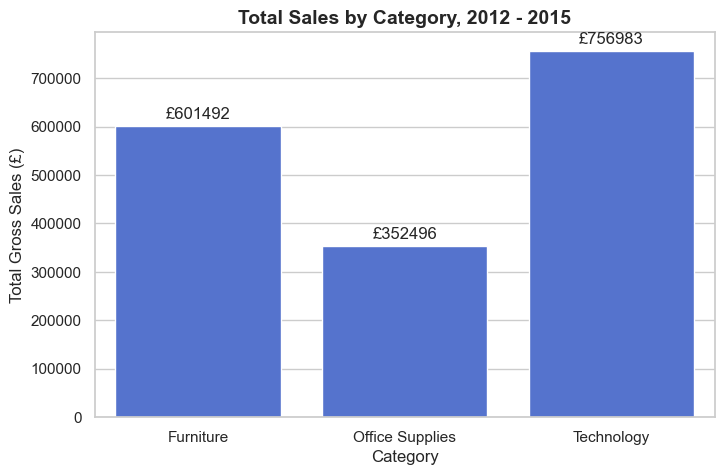

In [256]:
#grouping out data to use in the visual
sales_by_category = df.groupby('Category')['Sales'].sum().reset_index()

sns.set_theme(style='whitegrid')
plt.figure(figsize=(8, 5))

ax = sns.barplot(data=sales_by_category, x='Category', y='Sales', color='royalblue')

ax.bar_label(ax.containers[0], fmt= '£%.0f', padding=3)

plt.title('Total Sales by Category, 2012 - 2015', fontsize= 14, weight= 'bold')
plt.xlabel('Category', fontsize= 12)
plt.ylabel('Total Gross Sales (£)', fontsize= 12)

plt.show()

Overlook of our *Total Sales by Category*: **Furniture: £601,492, Office Supplies: £352,96, Technology: £756,983**

##### 2.2 Regional Sales Performance Heatmap by Product Category

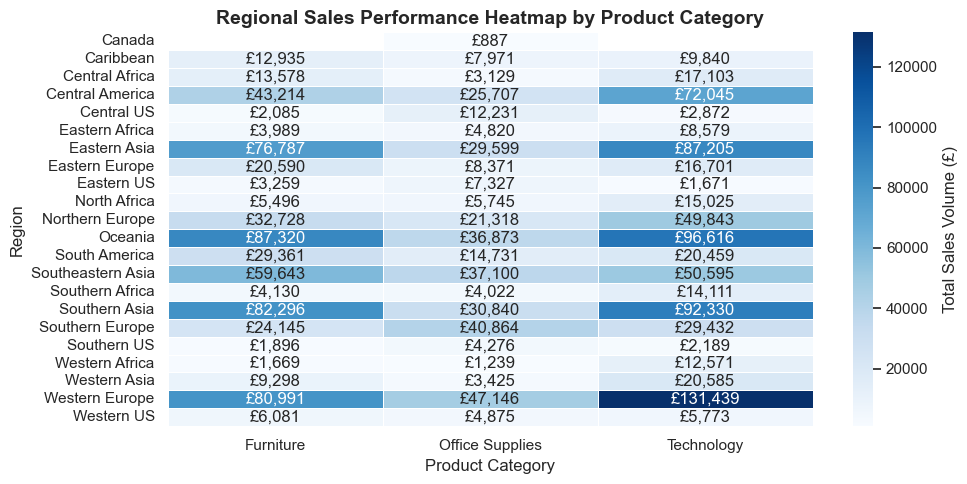

In [255]:
#creating a matrix to use for the heatmap, will be grouping by Category to simplify the view (though a look at subcatogies would be more insightful, when filtered by top 5 sub-categories)
regional_matrix = df.pivot_table(
    index= 'Region',
    columns= 'Category',
    values= 'Sales',
    aggfunc= 'sum'
)

figure_labels = regional_matrix.map(lambda x: f"£{x:,.0f}").values

sns.set_theme(style='white')
plt.figure(figsize=(10,5))

ax = sns.heatmap(
    data= regional_matrix,
    annot=figure_labels,
    fmt= '',
    cmap= 'Blues',
    linewidth= 0.5,
    cbar_kws= {'label': 'Total Sales Volume (£)'}
)

plt.title('Regional Sales Performance Heatmap by Product Category', fontsize= 14, weight= 'bold')
plt.xlabel('Product Category', fontsize= 12)
plt.ylabel('Region', fontsize= 12)

plt.xticks(rotation= 0)
plt.yticks(rotation= 0)

plt.tight_layout()
plt.show()

*Regional Sales Performance Heatmap by Product Category* - we have our profits broken down by region and category. **Clear standouts is Technology category, sitting at £131,439 for Western Europe, followed by Oceania with £96,616, and Southern Africa with £92,330.** We do have **some good numbers in Furniture category, here we have Oceania on top with £87,320, followed by Southern Asia with £82,296 and Western Europe just after at £80,991.** **Office Supplies is by far our weakest category Western Europe comes with the highest sales at only £47,146, followed by Southern Europe at £40,864 and Southern Asia coming in at £37,100.**

Through this overlook we can see that we have **a lot of changes that can be done in the categories of *Furniture* and *Office Supplies*. With sales numbers predominantly falling below £50,000 and not even breaking £50,000 at all.** There is some **room for improvement when it comes to our Technology sector, the standouts being Central, Eastern and Southern US with £2,872, £1,671 and £2,189 in sales.**

##### 2.3 Monthly Sales Revenue Over Time, 2012 - 2015

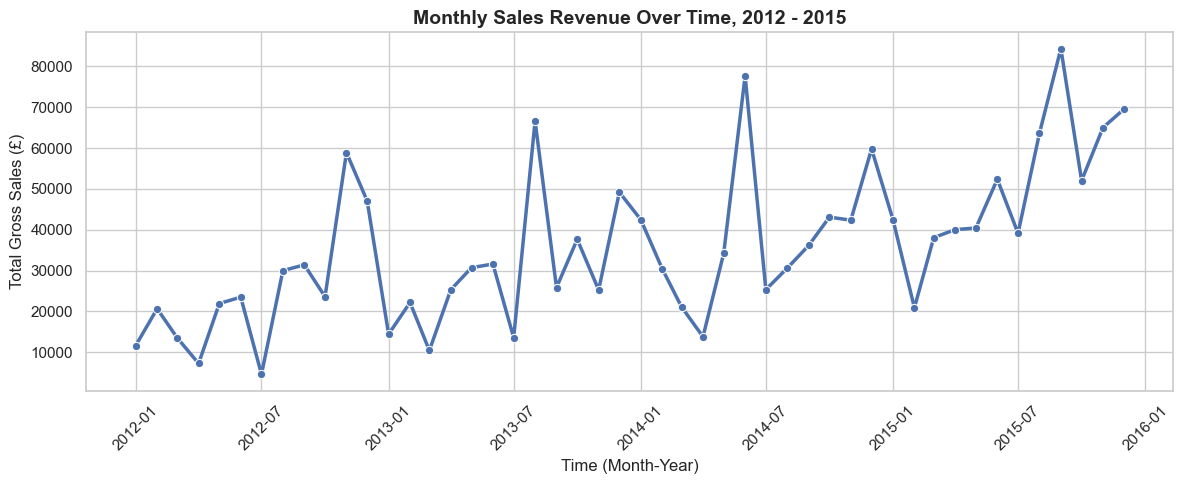

In [257]:
#converting out datetime column into a month-year format and saving it in a variable for the purpouse of the visual
monthly_sales = df.groupby(df['Order Date'].dt.to_period('M'))['Sales'].sum().reset_index()

#converting month-year into string format for readability
monthly_sales['Order Date'] = monthly_sales['Order Date'].dt.to_timestamp()

sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 5))

sns.lineplot(
    data= monthly_sales,
    x= 'Order Date',
    y= 'Sales', 
    marker= 'o', 
    linewidth= 2.5
)

plt.title('Monthly Sales Revenue Over Time, 2012 - 2015', fontsize= 14, weight= 'bold')
plt.xlabel('Time (Month-Year)', fontsize= 12)
plt.ylabel('Total Gross Sales (£)', fontsize= 12)

plt.xticks(rotation= 45)

plt.tight_layout()
plt.show()

*Total Sales Over Time, from 2012 - 2015*: we can see **some clear seasonality with some obvious spikes in sales and very clear dips**. Looking into both, in further depth could help us strategise to keep up the momentum of seasonal sales and mitigate our losses in the low times. However **overall we can see that our sales have been increasing year on year. Though 2014 has been unstable in it's ups and downs, 2015 is much more stable with more of a climb that in previous years.**

*A look into our marketing for 2015 could help us uncover any positive changes made vs previous years and help us keep such a strong upwards momentum going.*

##### 2.4 Time-Series Analysis: Monthly Sales Trends by Month and Seasonality

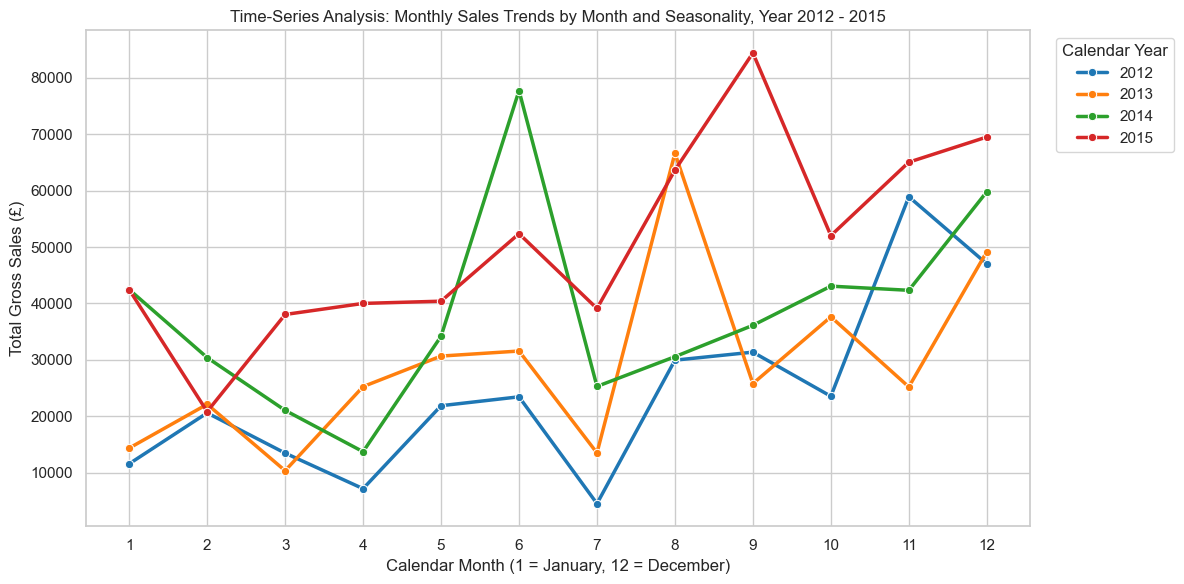

In [258]:
#creating two columns (year and month, respectively) for out visualisation
df['Year'] = df['Order Date'].dt.year
df['Month'] = df['Order Date'].dt.month

#group our sales for each year and month
monthly_trend= df.groupby(['Year', 'Month'])['Sales'].sum().reset_index()

sns.set_theme(style= 'whitegrid')
plt.figure(figsize= (12, 6))

sns.lineplot(
    data= monthly_trend,
    x= 'Month',
    y= 'Sales',
    hue= 'Year', 
    palette= 'tab10', 
    marker= 'o', 
    linewidth= 2.5
)

plt.title('Time-Series Analysis: Monthly Sales Trends by Month and Seasonality, Year 2012 - 2015')
plt.xlabel('Calendar Month (1 = January, 12 = December)')
plt.ylabel('Total Gross Sales (£)')

plt.xticks(range(1, 13)) 

plt.legend(title= 'Calendar Year', bbox_to_anchor= (1.02, 1), loc= 'upper left')

plt.tight_layout()
plt.show()

#I think overall this is a pretty clusterred chart, if possible we would discuss if all four years are necessary for the visual - at most I would 
#recommend to keep to the last two to three concecutive years max. alt the first year of operation vs the latest is another good comparison - this
#would depend on discussion with team/manager(s)/stakeholder(s) and what they wish to see - the progress over time alt the progress of sales across time.


*Time-Series Analysis: Monthly Sales Trends by Month and Seasonality, Year 2012 - 2015*. Here we can compare the previous years of operation against one another across the 12 months with some clear seasonal dips.

**Across the 2012 - 2014** we have **significant drops in gross sales for months of March and April, with the biggest drop by just arount £2,500 across the first three months of the year, comes in 2014.** **2015 dip comes earlier, in February and the fall in more drastic, falling by £2,000.**

**Across all the four years we can see sales increasing steadily, starting in May and peaking in June**. With the **highest peak in 2014 falling just below £8,000 in sales. 2015 though does not have the same dramatic peak, fallin at just above £5,000 for the same month of June.** Sales recovery is healthy coming our of the March dip and hold steady until the June peak, resulting in much more steady sales stream for the company.

There is **an interesting spike that occures only for the year 2013 with sales landing at arount £6,500 for the month of August** - while the other years either start recovering or peak. However, **in 2015 though we do not match 2013 in sales falling just below that years sales, it is part of a steady climb in sales for that year, peaking above all previously recorded years at £8,500 - an all time high for the company.** October sales fall down to just above £5,000 mark, they remain the highest for the company across all years, for that month.

**All time sales and healthy recovery continues through out the remaining two months of the year, ending the year at all time high of £7,000.** Even with the previous years seeing recovery for the same months, all peaking in the month of December. 

#### 2.5 Time-Series Analysis: Year-Month Sales: Seasonal Decomposition

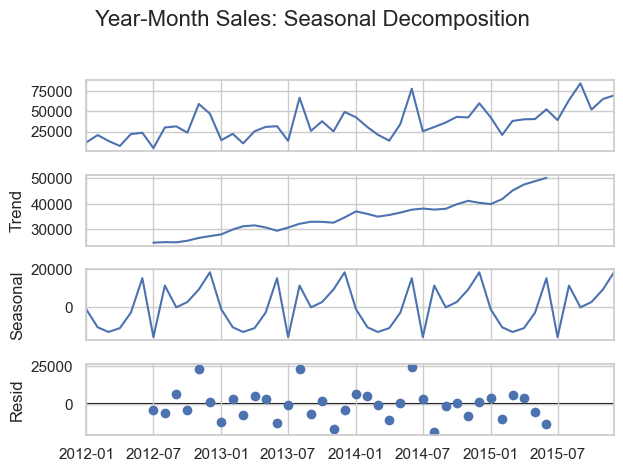

In [259]:
#converting month-year into string format for readability
monthly_sales['Order Date'] = pd.to_datetime(monthly_sales['Order Date'])

monthly_sales = monthly_sales.set_index('Order Date')

#seasonal decomposition of time-series of monthly sales
result = seasonal_decompose(monthly_sales, model= 'additive', period= 12)

fig = result.plot()
fig.suptitle('Year-Month Sales: Seasonal Decomposition', fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.95])

plt.show()

*Year-Month Sales Seasonal Decomposition* - here **we can see the strenthening our earlier observations with *'Monthly Sales Revenue Over Time, 2012 - 2015'* overall trend for the company is a steadly going up with a few peaks showing up on our trend line. In line with *'Time-Series Analysis: Monthly Sales Trends by Month and Seasonality, Year 2012 - 2015'* we can see a broader trend for our operational years with clear drops in the summer month(s) and a big swing from peak through recovery into another peak right at the begining of the summer.**

We do see quiet a few residual point in the *Resid* chart at the very bottom of our set, these are the points that we hope to investigate and limit with further analysis of the previously mentioned sub-category of Supplies and the number of products with the negative profit margin. Through these residuals we can see the work that we still need to perform in order to decrease the ammount of capitol lost on bleeding products and their corresponding overhead costs.

##### 2.6 Dual Analysis: Transaction Volume (Sales) vs Return (Profit)

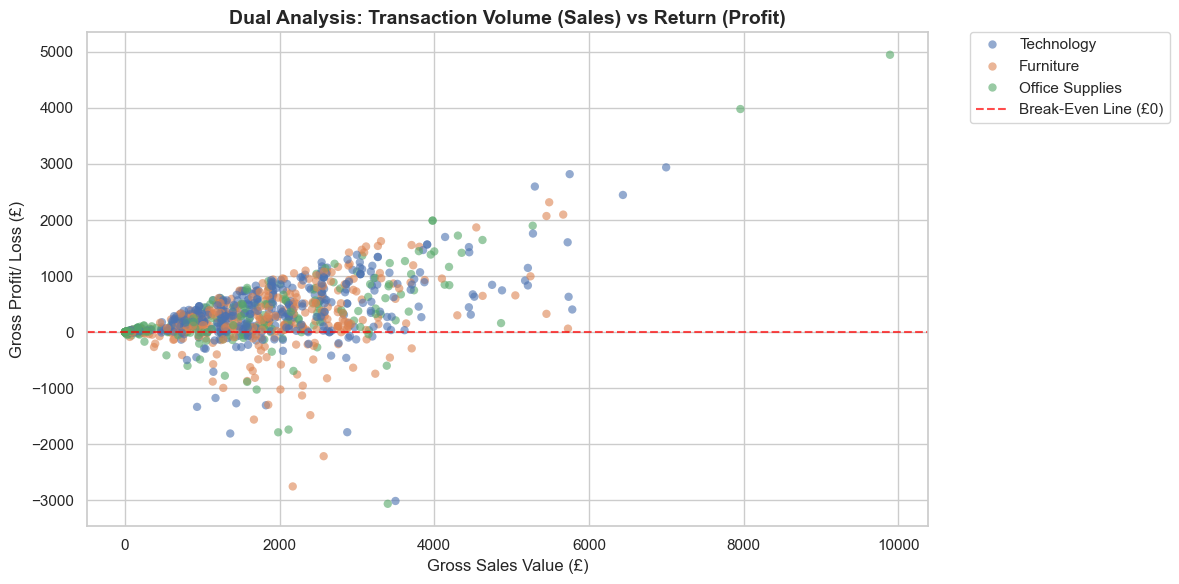

In [260]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x= 'Sales',
    y= 'Profit',
    hue= 'Category', 
    alpha= 0.6, 
    edgecolor='none'
)

plt.axhline(0, color='red', linestyle='--', linewidth= 1.5, alpha=0.7, label= 'Break-Even Line (£0)') #the breakeven line, added for clarity of profitable vs not

plt.title('Dual Analysis: Transaction Volume (Sales) vs Return (Profit)', fontsize= 14, weight= 'bold')
plt.xlabel('Gross Sales Value (£)', fontsize= 12)
plt.ylabel('Gross Profit/ Loss (£)', fontsize= 12)

plt.legend(bbox_to_anchor=(1.05, 1), loc= 'upper left', borderaxespad= 0.)

plt.tight_layout()
plt.show()

*'Dual Analysis: Transaction Volume (Sales) vs Return (Profit)'* Here we can visually see a comprehensive picture of the *Operational Friction Analysis: Negative Profit Products by Profit Margin %*. **Though a clear majority of our products fall above our basic break-even line, there still an alarming ammount of data points that fall right on and below the break-even line.We can see the direct effect of discounts and shipping costs alone make on our profitability - as seen in the Furniture data point and its high gross sales yet it is falling barely above the break-even line.** There is a lot of work for us to do in order to keep improoving our operations and refining our range of products.

#### 3.0 Data Integrity and Contraints Sign-Off

##### Data size

The size of our data is limited to only 1000 rows. This constitutes a small sample size of the companies numbers. This also put in constraints onto our conclutions as what we can see from the sample does not necessarily fully translates to the whole of the population.

##### Outlier retention

Outliers were left within the dataset in order to maintain the overal integrity of the volume and the profit gained. The macros of the portfolio are accurate to real-world for the time period, 2012 - 2015, as limited to the sample data set.

##### Outlier filtering

For the more detailed view, specificly Top 5/Bottom 5 Products, low-level outliers have been dynamically filtered out for the purposes of retaining and presenting the best performers with potential for scalability for the business.

##### Data Layout and dtype

Order Date and Ship Date had been converted into datetime dtypes, and we have dropped several columns (Row ID, Postal Code, City, State, Country, Market, Customer Name) both for security (privacy) concerns as well as performance optimisation of our current exploration. 

##### Profit Margin calculation

The negative profit margin calculations are made on the numbers and friction variables that are available to us within the limit of this data set, these do not include costs of other operational actions, thus the drag recorded in this analysis is far larger in resl-world than what is depicted here.

#### 4.0 Findings: Operational Volume vs Efficiency

Through our basic aggrigations we can tell that perational volumes are healthy, however our profit margins suffer quiet significantly. From further exploration of our friction variables - discounts (marketing/sales) and operational logistics (carriage fee/shipping cost) we have statistical confirmation of the following restictions having an average impact on our profitability:

**Promotional Price Erosion (Discount vs Profit)**
Shows a strong negative correlation coefficient of **-0.51**, proving that promotional discounts heavily restrain profits.

**Logistical Margin Drag (Shipping Cost vs Margin)**
Shows a more sevear correlation coefficient of **-0.60** across the Sub-Categories

**Conclution**
Though both variables somewhat restrict profits, logistical operational costs are the primary contraint on profitability out of the two variables looked at during the course of the analysis.

#### 4.1 Sub-Category Classification Matrix

**Powerhouses (High Volume + High Margin)**
**Phones** (£418K sales, 18.0% profit margin)
**Copiers** (£231K sales, 22.6% profit margin)

Show strong volumes of sales while resisting the promotional restrictions, with average discount rate at 7.3% and 4.1% respectively.

**Revenue Traps (High Volume + Low Margin)**
**Tables** (£180K sales, 7.3% profit margin)

Though sales volume is quiet healthy the profit margin is an alarming 7.3%, with average discount rate sitting at 16.8% and our logistics at £63.13, both of our variables are eating into profits.

**Neiche Gems (Low Volume + High Margin)**
**Fasteners** (£513 sales, 48.0% profit margin)
**Paper** (£1,8K sales, 44.4% profit margin)

Despite low sales volume, the profits sits on a veary healthy 44-48% whith only paper having any sort of promotional pricing (7.5%) and both of the sectors having very low logistical costs.

*We do not include the bookcases due to the volume of sales being at half of that of phones at £241K, while appliances have a low profit margin of 16.7%, which discounts them from being in the powerhouse bracket.*

#### 4.2 Negative Profit Products by Profit Margin % Matrix

We have **a number of products that both fall short of a significant sales volume as well as falling below 0% Profit Margin**. 

There are a handfull of such **products that bleed our margins with percentages obove -100% profit margin**:

Insertable Tab Indexes For Data Binders: £1.91 sales, **-169.6%	profit margin**, 80.0% discount, £0.37 shipping cost

Wilson Jones Four-Pocket Poly Binders:	£5.23 sales,	**-155.1%	profit margin**,	80.0% discount,	£0.43 shipping cost

Phones	Samsung Audio Dock, with Caller ID:	£934.25 sales,	**-142.5%	profit margin**,	60.0% discount,	£25.98 shipping cost

Furnishings	Tenex Chairmats For Use with Hard Floors:	£64.96 sales,	**-130.0%	profit margin**,	60.0% discount,	£0.88 shipping cost

Binders	Avery Recycled Flexi-View Covers for Binding Systems:	£76.94 sales,	**-127.5%	profit margin**,	76.7% discount,	£0.43 shipping cost

Tables	Barricks Conference Table, Rectangular:	£2,171.16 sales,	**-126.7%	profit margin**,	70.0% discount,	£48.76 shipping cost

To derive full impact of the various marketing campaigns, warehousing, distribution and other operational overhead a further indepth analysis needs to be conducted to fully diagnose the desiding factors on these products overall alternatively within specific regions in order to mitigate and hopefuly reallocate resources and capitol spent and lost on these (and other negative products) into profitable streams to encourage and continue their growth.

#### 4.3 Conclutions

**Primary bottle-neck**
Statistical validation confirms to the extend of our sample, that both promotional pricing (sitting at correlation of **-0.60%**) and logistical margins (correlation of **-0.51**) create a moderate impact on profitability, with high shipping costs represent largest structural contraint on the business as conclueded from the variable available to us within the scope of this analysis.

**Regional concentration**
From our regional heatmap we can see consentrated puchasing zones across all three of our cateories. With sigificant sectors of: **Oceanina** for **Furniture**, **Western Europe** for **Office Supplies** and **Western Europe** for **Technology**

**Seasonality**
Looking at time-series seasonality graphs, we can confirm sharp uptake in purchacing volumes during Q2, beginging of Q3 while dropping during the end of Q3 before peaking once again in Q4, across the given years of 2012 - 2015. This showcases the operational stress peaks. 

#### 5.0 Summary

Jumping from our overal totals we can see that volume is not the primary issue, confirmed by the time-series graph(s) there is a steady increase in sales year by year. We can see further confirm from our *Monthly Sales Revenue Over Time* graph. With out primary profits coming from *Technology* category followed by *Furniture* - which also divercifies our operations across regions. Showing a strong potential for establishing stronger foothold in the international markets within the scope of our Furniture category. With a close look needs to be taken on Office Supplies category in order to rectify a clear shortfall in sales as seen withing this sample data.
    Looking deeper into the numbers we can also see that at the current moment the biggest hindrances to further finantial growth for the company are the friction variables. We were working with promotional pricing and logistical costs for this analysis, though further work should be performed in order to gain full insight on the issue and its complete list of variables. However, we can recommend limmiting application of volume based discounts to mitigate profit erosion, as well as allocate resources into discovery of further logistics costs, and potentially renagotiate fees with partners.
    Further more we can recomend increacing the stockholding for paper and fastenings categories as these sub-categories hold very strong profit margin with low operational costs.
    Finaly, it would be lucrative to look into the seasonality of Q2 and Q4 across the board - taking advantage of sales uptake can result in increace in volume.